# v103 line: line contact on a periodic strip against Hertz

**Question.** Does the SlipPY BEM, through `slippy_bridge` (one period of a strip periodic along the line,
frequency kernel), reproduce the plane-strain Hertz contact of two cylinders (half-width `b`, peak `p0`,
profile `p(x)`; Johnson 1985 Eqs (4.43)-(4.45), PDF p. 111)?

**System.** Steel rollers R 10 and 20 mm, 1e5 N/m, load control (the approach of a line is not defined
locally: not compared). **Reference.** r02 `hertz(..., line=True)`.

**Criteria (README section 6, fixed before the run).** At `b/h >= 16` and a domain half-length `>= 4 b`:
C3 `p0` within `M^(-3/2)`, C4 `b` within `1/M`, `M = 2b/h`. RECORD: `eps_p`, the load balance, Johnson's
`p0/p_m = 4/pi`, coarser grids and smaller domains.

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v100_dry_contact.v103_hertz_line import study

out = study.run()
print(format_table((("sweep", "sweep", "s"), ("b_over_h", "b/h", ".1f"), ("span_x", "span", ".2f"), ("id", "id", "s"),
                    ("quantity", "quantity", "s"), ("measured", "BEM", ".6g"), ("reference", "reference", ".6g"),
                    ("rel_err", "err [%]", "+.4f", 100.0), ("tol", "tol [%]", ".3f", 100.0),
                    ("verdict", "verdict", "s")), out["check"]))

sweep   b/h   span  id  quantity          BEM   reference  err [%]  tol [%]  verdict
-----  ----  -----  --  --------  -----------  ----------  -------  -------  -------
    h  11.2   4.00  C3        p0  7.44375e+08  7.4224e+08  +0.2876    0.938   RECORD
    h  11.2   4.00  C4         b  8.49743e-05   8.577e-05  -0.9277    4.448   RECORD
    h  11.2   4.00  C5     eps_p   0.00749114           0  +0.7491        -   RECORD
    h  11.2   4.00  C6         w       100000      100000  +0.0000        -   RECORD
    h  11.2   4.00  L1    p0/p_m      1.26506     1.27324  -0.6428        -   RECORD
    h  22.5   4.00  C3        p0  7.44526e+08  7.4224e+08  +0.3080    0.332     PASS
    h  22.5   4.00  C4         b  8.51193e-05   8.577e-05  -0.7587    2.224     PASS
    h  22.5   4.00  C5     eps_p   0.00492187           0  +0.4922        -   RECORD
    h  22.5   4.00  C6         w       100000      100000  +0.0000        -   RECORD
    h  22.5   4.00  L1    p0/p_m      1.26747     1.27324  -0.453

## Errors against the grid spacing (half-length 4) and the domain (`b/h` 16 asked); pressure across the line

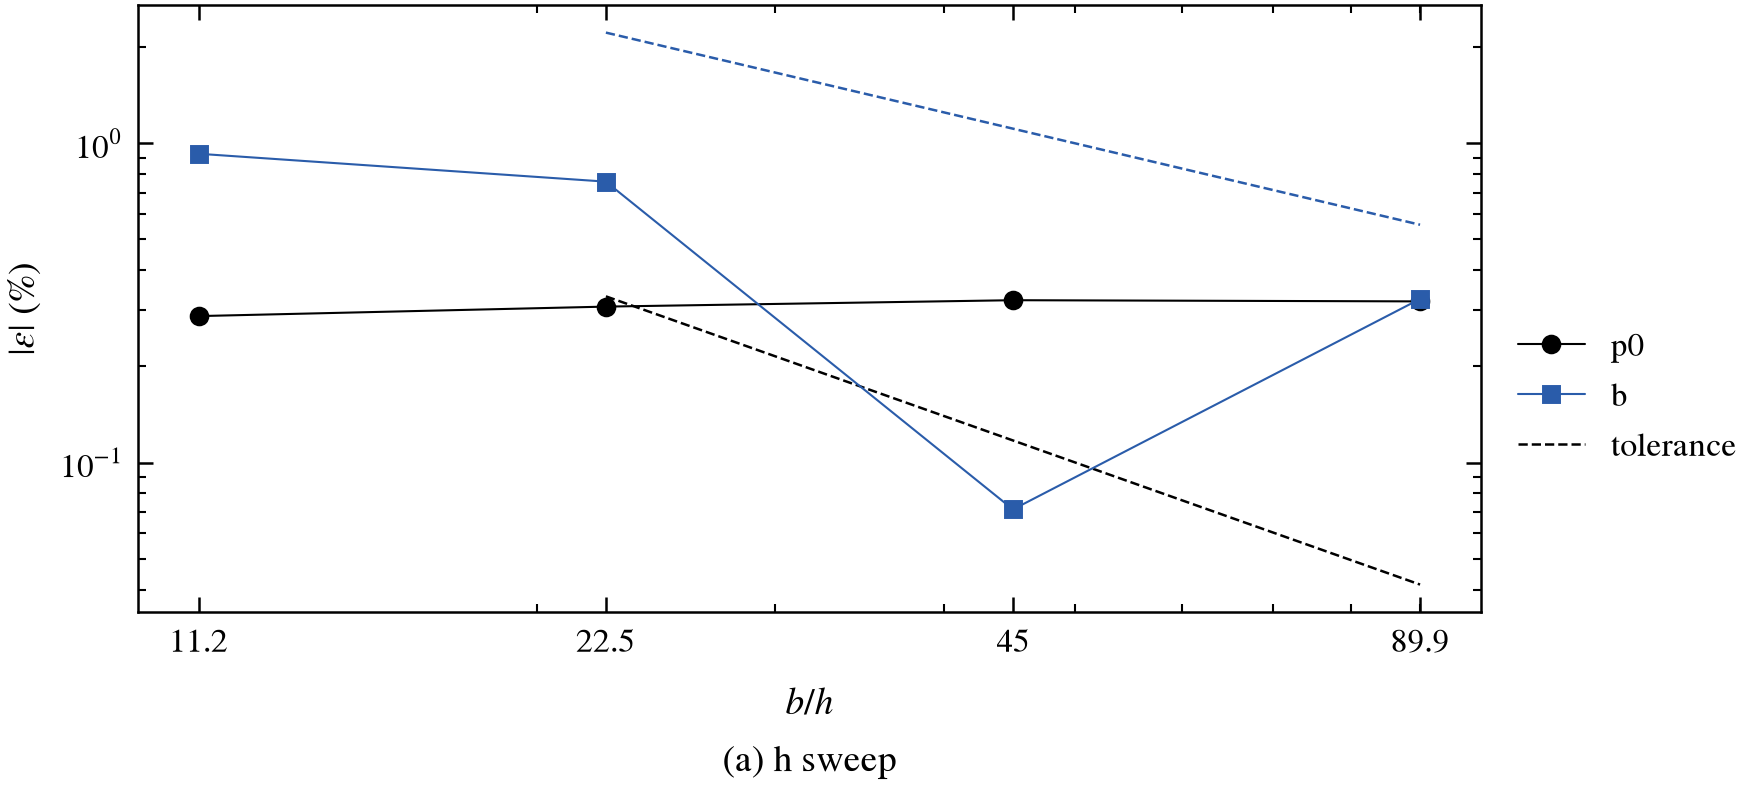

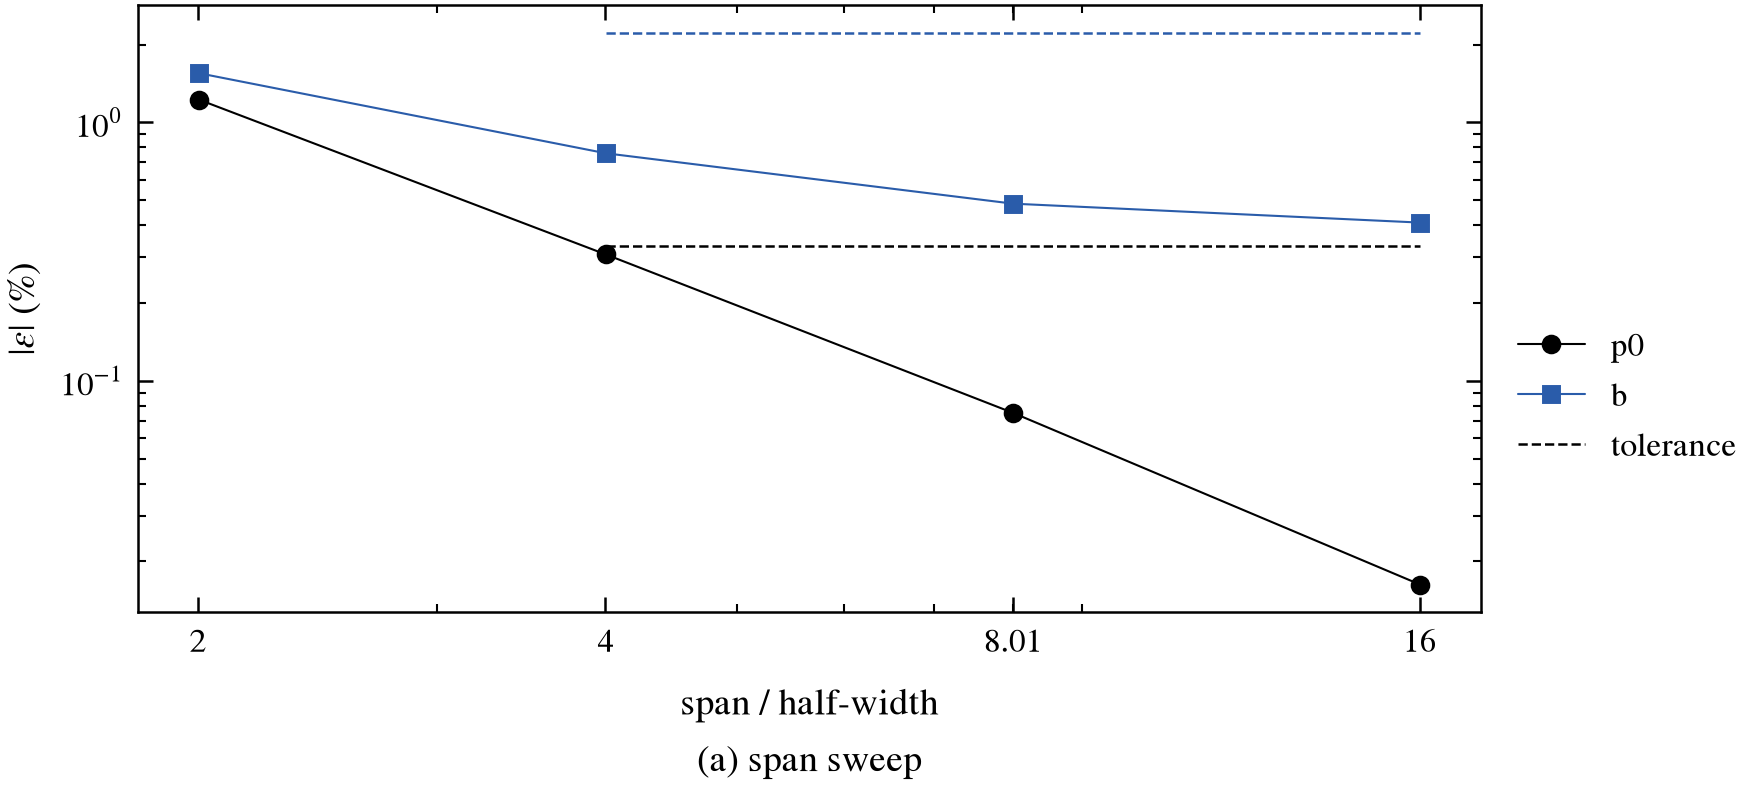

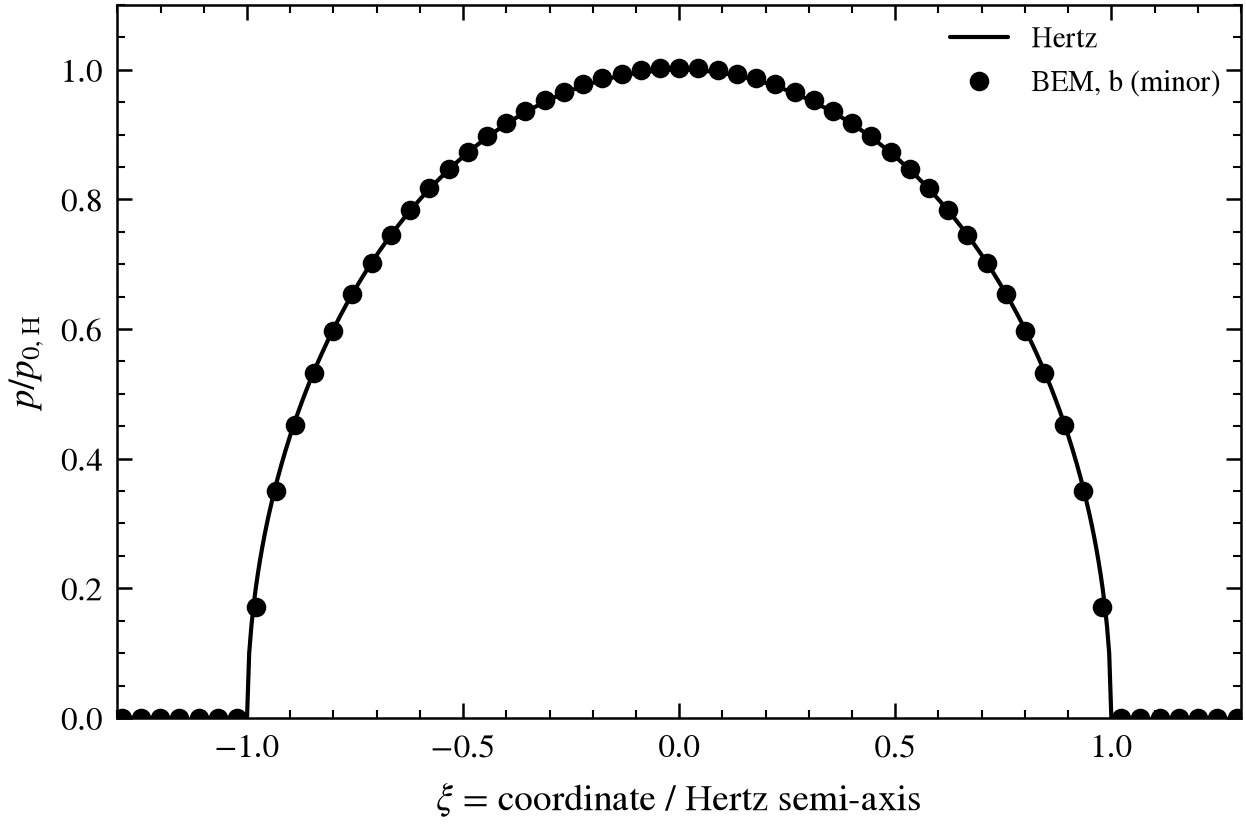

In [2]:
for path in out["figures"]:
    display(Image(filename=str(path)))

In [3]:
judged = [r for r in out["check"] if r["verdict"] != "RECORD"]
print(f"judged {len(judged)}, MISS {sum(r['verdict'] == 'MISS' for r in judged)}")

judged 12, MISS 2
